# Trabalho Prático - Notebook do grupo

**Inteligência Artificial - Graduação** · Prof. Bruno Nogueira · FACOM/UFMS · 2026/2

**Grupo:** CHATBOT RUMO · **Tema:** Chatbot sobre mobilidade acadêmica

---

Este é o notebook **entregável** do grupo. Ele precisa rodar do início ao fim
("Kernel → Restart & Run All") e **regerar os modelos** salvos em `modelos/`. A
estrutura segue o `00_exemplo_biblioteca.ipynb`; consulte-o sempre que tiver
dúvida.

Marcadores usados aqui:

* `🔨 TODO` - algo que o grupo precisa fazer/decidir;
* `📝 RELATÓRIO` - um resultado que deve aparecer (e ser discutido) no artigo.

Requisitos mínimos de cada seção estão no enunciado. Pode acrescentar seções,
células e análises à vontade - só não remova as seções numeradas.

---
## 0. Ambiente

In [102]:
import os
import subprocess
import sys
from pathlib import Path

# 🔨 TODO (só para o Colab): endereço do repositório do grupo
REPO_URL = "https://github.com/SEU_USUARIO/SEU_REPOSITORIO.git"

if "google.colab" in sys.modules:
    pasta = Path("/content") / Path(REPO_URL).stem
    if not pasta.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(pasta)], check=True)
    os.chdir(pasta)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

raiz = Path.cwd()
while not (raiz / "chatbot").is_dir():
    if raiz.parent == raiz:
        raise RuntimeError("Rode este notebook de dentro do repositório do trabalho.")
    raiz = raiz.parent
os.chdir(raiz)
sys.path.insert(0, str(raiz))

In [103]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from chatbot.avaliacao import avaliar, tabela_resumo
from chatbot.config import carregar_config
from chatbot.dados import adicionar_escopo, carregar_dados, resumo, validar_dados, vazamento
from chatbot.grafo import Conversa, construir_grafo
from chatbot.modelos import carregar_classificadores, salvar_classificadores
from chatbot.representacoes import tfidf_caracteres, tfidf_palavras
from chatbot.rotulos import CLASSES_ESCOPO

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
CORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
pd.set_option("display.max_colwidth", 80)

---
## 1. Configuração

In [104]:
config = carregar_config("grupo.yaml")
print("Grupo:", config.grupo, "| Tema:", config.tema)
pd.DataFrame([(i.nome, i.descricao) for i in config.intencoes.values()], columns=["intenção", "descrição"])
print("Limiar de confiança do tema:", config.limiar_tema)
pd.DataFrame(
    [(i.nome, i.descricao, i.resposta[:70] + "...") for i in config.intencoes.values()],
    columns=["intenção", "descrição", "resposta (início)"],
)

Grupo: chatbot RUMO | Tema: Chatbot de mobilidade acadêmica e intercâmbio da UFMS
Limiar de confiança do tema: 0.42


,intenção,descrição,resposta (início)
0,proficiencia,Exigência de idioma e certificados aceitos,"Depende do destino: cada vaga define o idioma e o nível, geralmente B1..."
1,custos_auxilio,"Custo do intercâmbio, bolsas e auxílios financeiros","Em geral não há mensalidade, mas passagem, visto, seguro, moradia e al..."
2,destino_parcerias,Universidades conveniadas e países disponíveis,As universidades parceiras e as vagas estão no Quadro de Oportunidades...
3,mobilidade_nacional,Cursar um período em outra universidade brasileira,Pelo Programa Andifes você pode cursar até dois semestres em outra fed...
4,documentos_viagem,"Visto, passaporte, seguro saúde, vacinas e exigências de entrada em outros p...","Você vai precisar de passaporte, visto (se o país exigir) e seguro saú..."
5,inscricao,"Editais abertos, prazos e formas de me candidatar","A inscrição é feita pelo SIGProj (sigproj.ufms.br), escolhendo uma uni..."
6,requisitos,"Requisitos acadêmicos para participação (CRA, semestre, vínculo)","Na graduação, é preciso estar matriculado, ter cursado entre 20% e 80%..."


---
## 2. Dados

O treino contém 1270 frases, 303 humanas e 967 geradas pela LLM utilizando o script disponibilizado. Das 2861 frases que geramos, por volta de 967, por intenção, foram escolhidas para o treino após revisão. As frases humanas vieram de um formulário montado por nós que foi respondido por 44 pessoas. O teste tem 199 frases, todas humanas. Os negativos difíceis são sobre assuntos relacionados a UFMS.

📝 RELATÓRIO: tabela intenção × origem do treino e do teste.

In [105]:
treino = adicionar_escopo(carregar_dados(config.treino), config)
teste = adicionar_escopo(carregar_dados(config.teste), config)
print("Problemas no treino:", validar_dados(treino, config) or "nenhum")
print("Problemas no teste: ", validar_dados(teste, config) or "nenhum")
print("Vazamento treino→teste:", vazamento(treino, teste) or "nenhum")
display(resumo(treino))
display(resumo(teste))

Problemas no treino: nenhum
Problemas no teste:  nenhum
Vazamento treino→teste: nenhum


origem,humano,llm,total
intencao,,,
chitchat,10,140,150
custos_auxilio,21,99,120
destino_parcerias,40,80,120
documentos_viagem,21,98,119
fora_dominio,129,152,281
inscricao,44,76,120
mobilidade_nacional,7,113,120
proficiencia,5,115,120
requisitos,26,94,120


origem,humano,total
intencao,,
chitchat,34,34
custos_auxilio,18,18
destino_parcerias,18,18
documentos_viagem,18,18
fora_dominio,45,45
inscricao,18,18
mobilidade_nacional,15,15
proficiencia,15,15
requisitos,18,18


### Gerando frases de treino com o LLM (opcional)

Rode no terminal (ou descomente a célula abaixo). As frases vão para
`dados/gerados_llm.csv` e os prompts ficam registrados em `dados/prompts_llm.md`.
**Revise tudo** antes de copiar para o `treino.csv`; nunca use no teste; declare no
`USO_DE_IA.md`.

In [106]:
# Para rodar daqui, tire o "#" das linhas abaixo (gasta créditos da chave do grupo):
# subprocess.run([sys.executable, "scripts/gerar_dados_llm.py", "--n", "10"], check=True)
# gerados = pd.read_csv("dados/gerados_llm.csv")
# gerados.sample(15)

### Analise exploratória
No primeiro gráfico está mostrando a distribuição das frases pelos grupos, (domínio, chitchat, fora_dominio), sendo 839 pra domínio, 281 fora de domínio e 150 de chitchat.

Devido ao desbalanceamento das classes teremos que usar F1 Macro como medida.

As 7 intenções tem 120 frases cada. As mensagens de chitchat são as mais curtas com média de 7.1 palavras. As frases que geramos por LLM são mais longas com média de 11.2 palavras que as humanas que tem 8.5 palavras, isso demonstra uma distinção de estilo em relação ao teste, que é formado 100% por frases humanas. As palavras mais frequentes de cada intenção são coerentes com o assunto em si.

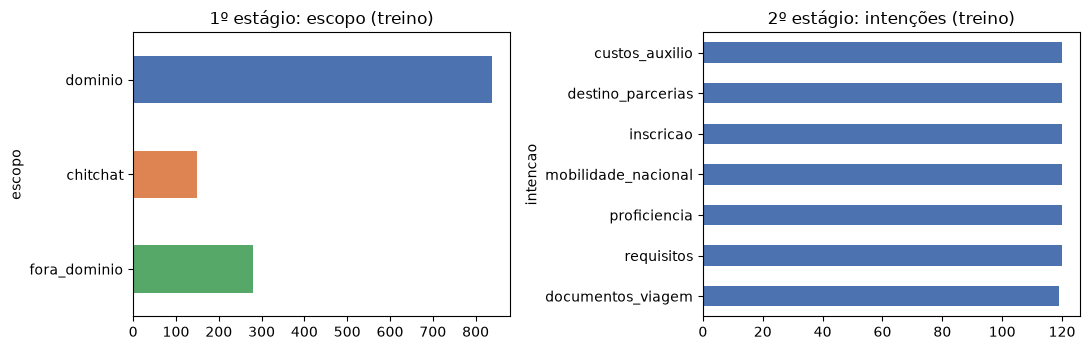

,mean,min,max
intencao,,,
chitchat,7.1,1,18
custos_auxilio,11.2,2,24
destino_parcerias,9.8,3,27
documentos_viagem,12.3,3,26
fora_dominio,9.8,2,30
inscricao,9.8,2,24
mobilidade_nacional,15.4,2,31
proficiencia,10.2,3,24
requisitos,11.3,2,24


,mean,min,max
origem,,,
humano,8.5,1,30
llm,11.2,1,31


chitchat             ['voce', 'foi', 'bom', 'ate', 'bot', 'estou', 'tudo', 'hoje']
custos_auxilio       ['intercambio', 'bolsa', 'auxilio', 'ufms', 'algum', 'despesas', 'quanto', 'financeiro']
destino_parcerias    ['ufms', 'universidades', 'paises', 'intercambio', 'conveniadas', 'instituicoes', 'fazer', 'convenio']
documentos_viagem    ['visto', 'preciso', 'pais', 'passaporte', 'intercambio', 'seguro', 'levar', 'antes']
fora_dominio         ['onde', 'faco', 'preciso', 'pais', 'por', 'curso', 'hoje', 'vida']
inscricao            ['edital', 'intercambio', 'processo', 'inscricao', 'onde', 'prazo', 'quando', 'candidatura']
mobilidade_nacional  ['outra', 'universidade', 'ufms', 'disciplinas', 'materias', 'destino', 'periodo', 'cursar']
proficiencia         ['certificado', 'proficiencia', 'idioma', 'ingles', 'comprovar', 'nivel', 'aceito', 'preciso']
requisitos           ['participar', 'intercambio', 'semestre', 'cra', 'preciso', 'estou', 'vinculo', 'disciplinas']


,texto,origem
92,Qual o valor da bolsa de iniciação científica?,humano
93,Posso me transferir para outro curso da UFMS?,humano
94,Como transfiro meu curso em definitivo para outra universidade,humano
95,Quais documentos são necessários para rematrícula,humano
114,qual cidades são ricas em recursos históricos,humano
121,para qual federal eu posso ir e que seja forte para meu curso?,humano
185,Qual área é responsável pelos estágios dentro da UFMS?,humano
195,como estagiar na ufms?,humano
214,qual universidade e referência no meu curso,humano
1120,Poderia explicar como funciona o processo de transferência entre cursos dent...,llm


In [107]:
from collections import Counter
from chatbot.texto import normalizar

# Distribuição das classes
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.6))
treino["escopo"].value_counts().reindex(CLASSES_ESCOPO).plot.barh(ax=eixos[0], color=CORES[:3])
eixos[0].set_title("1º estágio: escopo (treino)"); eixos[0].invert_yaxis()
treino.loc[treino["escopo"] == "dominio", "intencao"].value_counts().plot.barh(ax=eixos[1], color=CORES[0])
eixos[1].set_title("2º estágio: intenções (treino)"); eixos[1].invert_yaxis()
plt.tight_layout(); plt.show()

# Tamanho das mensagens por classe e por origem
tam = treino.assign(n_palavras=treino["texto"].str.split().str.len())
display(tam.groupby("intencao")["n_palavras"].agg(["mean", "min", "max"]).round(1))
display(tam.groupby("origem")["n_palavras"].agg(["mean", "min", "max"]).round(1))

# Palavras mais frequentes por intenção
STOP = {"que", "como", "para", "pra", "com", "uma", "tem", "posso", "qual", "quais", "sobre", "minha", "meu", "nao", "sao", "ser", "mais"}
for intencao, g in treino.groupby("intencao"):
    c = Counter(p for t in g["texto"] for p in normalizar(t).split() if len(p) > 2 and p not in STOP)
    print(f"{intencao:20s}", [p for p, _ in c.most_common(8)])

# Exemplos de negativos difíceis (fora_dominio com palavras do tema)
fora = treino[treino["intencao"] == "fora_dominio"]
fora[fora["texto"].str.contains("bolsa|edital|inscri|ufms|curso|matr", case=False)][["texto", "origem"]].head(10)


---
## 3. Representações de texto

Fizemos a comparação com 4 representações TF-IDF. Todas são normalizadas antes de serem utilizadas

"TF-IDF palavras" : Considera palavras isoladas e pares de palavras\
"TF-IDF palavras (só unigramas)" : Considera palavras isoladas, sendo um "saco de palavras soltas"\
"TF-IDF sem stopwords" : 1-2 gramas, removendo palavras muito comuns como artigos, preposições e conjunções. Isso antes de formar os pares\
"TF-IDF caracteres" : Considera pedaços de 2 a 5 letras dentro de cada palavra, sendo mais robusto a erros de digitação , variação e abreviação

In [108]:
from chatbot.texto import STOPWORDS

REPRESENTACOES = {
    "TF-IDF palavras": tfidf_palavras,
    "TF-IDF caracteres": tfidf_caracteres,
    "TF-IDF palavras sem stopwords": lambda: tfidf_palavras(stop_words=STOPWORDS),
    "TF-IDF palavras (só unigramas)": lambda: tfidf_palavras(ngram_range=(1,1)),
}


---
## 4. Classificador de escopo (dominio / chitchat / fora_dominio)

Adicionamos os classificadores KNN com N=5, Naive Bayes e SVM.

📝 RELATÓRIO: tabela/gráfico da comparação, com média e desvio entre folds.

In [109]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

CLASSIFICADORES = {
    "Regressão logística": lambda: LogisticRegression(C=10, max_iter=2000),
    "Rede neural (MLP)": lambda: MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3, max_iter=600,
                                               random_state=RANDOM_STATE),
    "Árvore de decisão": lambda: DecisionTreeClassifier(random_state=RANDOM_STATE),
    "K Vizinhos mais próximos (KNN)": lambda: KNeighborsClassifier(n_neighbors= 5, metric="cosine"),
    "Naive Bayes": lambda: BernoulliNB(alpha=1.0),
    "SVM Linear": lambda: SVC(kernel="linear", C=1, probability=True),
}


def comparar(textos, rotulos):
    linhas = []
    for nome_rep, rep in REPRESENTACOES.items():
        for nome_clf, clf in CLASSIFICADORES.items():
            pipe = Pipeline([("vetorizador", rep()), ("classificador", clf())])
            r = cross_validate(pipe, textos, rotulos, cv=cv, scoring=["f1_macro", "accuracy"],
                               return_train_score=True, n_jobs=-1)
            linhas.append({"representação": nome_rep, "classificador": nome_clf,
                           "F1 macro (CV)": r["test_f1_macro"].mean(), "desvio": r["test_f1_macro"].std(),
                           "acurácia (CV)": r["test_accuracy"].mean(),
                           "F1 macro (treino)": r["train_f1_macro"].mean()})
    return pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False).reset_index(drop=True)


tab_escopo = comparar(treino["texto"], treino["escopo"])
tab_escopo.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF caracteres,Regressão logística,0.886,0.025,0.908,1.000
1,TF-IDF caracteres,SVM Linear,0.886,0.021,0.908,0.974
2,TF-IDF caracteres,Rede neural (MLP),0.884,0.024,0.906,1.000
3,TF-IDF palavras sem stopwords,Rede neural (MLP),0.874,0.024,0.900,1.000
4,TF-IDF caracteres,Naive Bayes,0.869,0.020,0.893,0.927
5,TF-IDF palavras (só unigramas),SVM Linear,0.868,0.029,0.895,0.982
6,TF-IDF palavras,Rede neural (MLP),0.865,0.019,0.893,1.000
7,TF-IDF palavras (só unigramas),Regressão logística,0.863,0.032,0.893,1.000
8,TF-IDF palavras sem stopwords,SVM Linear,0.859,0.026,0.890,0.996
9,TF-IDF palavras (só unigramas),Rede neural (MLP),0.858,0.036,0.887,1.000


### Comparação

Testamos 6 algoritmos (Regressão Logística, MLP, DT, KNN, Naive Bayes e SVM Linear) com as 4 representações definidas anteriormente, utilizando validação cruzada estratificada de 5 folds no treino.

A representação de **TF-IDF caracteres** foi a que gerou melhor resultado para quase todos os algoritmos. Os que obtiveram melhor desempenho foram MLP (F1 = 0.884), SVM linear (F1 = 0.886) e regressão logística (F1 = 0.886), todos com a representação de caracteres.

### Classificadores escolhidos e modelo de representação

Com base na tabela acima, escolhemos MLP, SVM e Regressão Logística todas com a representação TF-IDF caracteres.


In [110]:
def curva_validacao(busca, param, titulo, log=True):
    """Curva de validação de um hiperparâmetro, com os demais fixos no melhor valor."""
    res = pd.DataFrame(busca.cv_results_)
    for p, v in busca.best_params_.items():          # fixa os outros parâmetros no melhor valor
        if p != param:
            res = res[res["param_" + p].astype(str) == str(v)]
    res = res.assign(x=res["param_" + param].astype(float)).sort_values("x")

    plt.figure(figsize=(6, 3.8))
    plt.errorbar(res["x"], res["mean_train_score"], yerr=res["std_train_score"], fmt="o-", color=CORES[0], label="treino")
    plt.errorbar(res["x"], res["mean_test_score"], yerr=res["std_test_score"], fmt="s-", color=CORES[3], label="validação (CV)")
    if log:
        plt.xscale("log")
    plt.xlabel(param.split("__")[1]); plt.ylabel("F1 macro"); plt.ylim(0, 1.02)
    plt.title(titulo); plt.legend(); plt.show()


In [111]:
grades_escopo = {
    "Regressão logística": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        param_grid={"vetorizador__ngram_range": [(2, 4), (2, 5), (3, 6)],
                    "classificador__C": [0.01, 0.1, 1, 3, 10, 30, 100]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),

    "SVM linear": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", SVC(kernel="linear", probability=True))]),
        param_grid={"vetorizador__ngram_range": [(2, 4), (2, 5)],
                    "classificador__C": [0.01, 0.1, 1, 10, 100]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),

    "Rede neural (MLP)": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()),
                  ("classificador", MLPClassifier(max_iter=600, random_state=RANDOM_STATE))]),
        param_grid={"classificador__hidden_layer_sizes": [(32,), (64,), (128,)],
                    "classificador__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),
}

for nome, busca in grades_escopo.items():
    busca.fit(treino["texto"], treino["escopo"])
    print(f"{nome:22s} {busca.best_params_}  F1 = {busca.best_score_:.3f}")


Regressão logística    {'classificador__C': 30, 'vetorizador__ngram_range': (3, 6)}  F1 = 0.900
SVM linear             {'classificador__C': 1, 'vetorizador__ngram_range': (2, 5)}  F1 = 0.886
Rede neural (MLP)      {'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (32,)}  F1 = 0.889


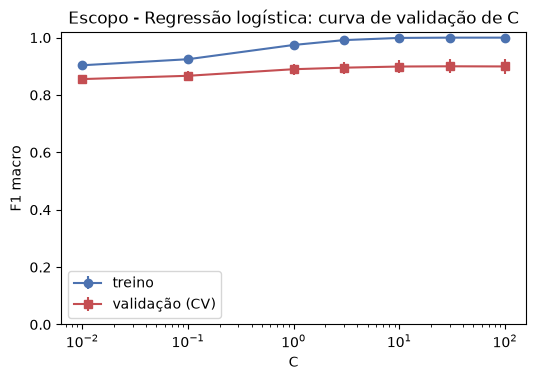

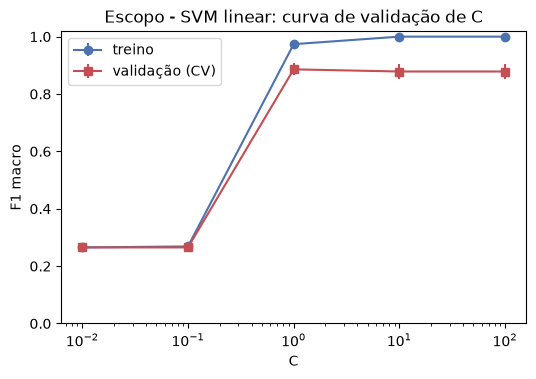

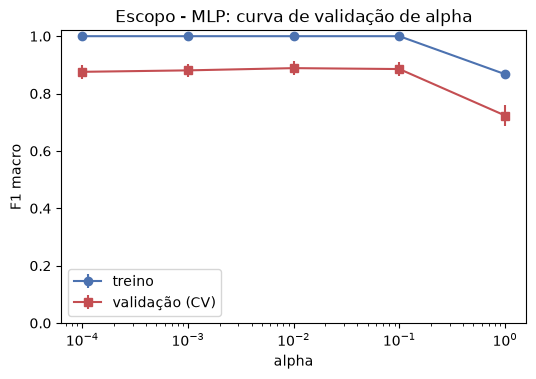

In [112]:
curva_validacao(grades_escopo["Regressão logística"], "classificador__C", "Escopo - Regressão logística: curva de validação de C")
curva_validacao(grades_escopo["SVM linear"], "classificador__C", "Escopo - SVM linear: curva de validação de C")
curva_validacao(grades_escopo["Rede neural (MLP)"], "classificador__alpha", "Escopo - MLP: curva de validação de alpha")


### Ajuste dos hiperparâmetros

Com o GridSearchCV ajustamos os hiperparâmetros de cada modelo com as seguintes grades:

* regressão logística: `C` ∈ {0,01; 0,1; 1; 3; 10; 30; 100} e n-gramas de caracteres (2–4, 2–5, 3–6), com `class_weight="balanced"`;
* SVM: `C` ∈ {0,01 … 100} e n-gramas (2–4, 2–5);
* MLP: `alpha` ∈ {1e-4 … 1} e camada oculta com 32, 64 ou 128 neurônios.

Usamos `class_weight="balanced"` porque as classes são desbalanceadas (839 / 281 / 150). Esse parâmetro dá mais peso a `chitchat` e `fora_dominio` e reduz o falso aceite.

As curvas de validação mostram o compromisso entre viés e variância. No SVM, com `C` ≤ 0,1 a regularização é tão forte que o modelo prevê tudo como `dominio` (F1 ≈ 0,27): viés alto. A regressão logística balanceada não sofre esse colapso e já parte de F1 ≈ 0,86 com `C` = 0,01. Nela, o F1 de treino é 0,97 em `C` = 1 e chega a 1,0 a partir de `C` = 10, enquanto o de validação se estabiliza em ~0,90. A partir daí, aumentar `C` só faz o modelo decorar o treino. Na MLP, o desempenho é estável até `alpha` = 0,1 e cai com `alpha` = 1 (viés).


In [113]:
def taxas_escopo(y, prev):
    fora = y != "dominio"
    return {"falso aceite": ((prev == "dominio") & fora).sum() / fora.sum(),
            "falsa recusa": ((prev != "dominio") & ~fora).sum() / (~fora).sum()}

linhas = []
for nome, busca in grades_escopo.items():
    prev = cross_val_predict(busca.best_estimator_, treino["texto"], treino["escopo"], cv=cv, n_jobs=-1)
    linhas.append({
        "modelo": nome,
        "melhores parâmetros": busca.best_params_,
        "F1 macro (CV)": busca.best_score_,
        "desvio": busca.cv_results_["std_test_score"][busca.best_index_],
        "F1 macro (treino)": busca.cv_results_["mean_train_score"][busca.best_index_],
        **taxas_escopo(treino["escopo"].to_numpy(), prev),
    })

resumo_busca_escopo = pd.DataFrame(linhas).sort_values("F1 macro (CV)", ascending=False)
display(resumo_busca_escopo.style.format({
    "F1 macro (CV)": "{:.3f}", "desvio": "{:.3f}", "F1 macro (treino)": "{:.3f}",
    "falso aceite": "{:.1%}", "falsa recusa": "{:.1%}",
}))

clf_escopo = grades_escopo["Regressão logística"].best_estimator_


,modelo,melhores parâmetros,F1 macro (CV),desvio,F1 macro (treino),falso aceite,falsa recusa
0,Regressão logística,"{'classificador__C': 30, 'vetorizador__ngram_range': (3, 6)}",0.900,0.025,1.000,14.8%,4.2%
2,Rede neural (MLP),"{'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (32,)}",0.889,0.025,1.000,18.1%,3.3%
1,SVM linear,"{'classificador__C': 1, 'vetorizador__ngram_range': (2, 5)}",0.886,0.021,0.974,20.2%,2.3%


### Escolha do modelo

Os três finalistas ficaram empatados no F1 macro: de 0,886 a 0,900, uma diferença menor que o desvio entre os folds (0,021–0,025).

Desempatamos pelo erro mais grave no nosso domínio, o **falso aceite**. Aqui há diferença: 14,8% na regressão logística, 18,1% na MLP e 20,2% no SVM.

Escolhemos a **regressão logística** com C = 30, n-gramas de caracteres de 3 a 6 e `class_weight="balanced"`: falso aceite de 14,8% e falsa recusa de 4,2%. Ela empata no F1 e é a melhor no falso aceite. O balanceamento troca um pouco de falsa recusa por menos falso aceite, que é a troca certa para o nosso caso. Além disso, ela é determinística, rápida e interpretável.

Mesmo o melhor modelo ainda aceita ~15% das mensagens fora do domínio. A causa principal continua sendo a falta de negativos difíceis no treino: perguntas sobre outros assuntos da UFMS com vocabulário parecido com o nosso.


📝 RELATÓRIO: matriz de confusão (validação cruzada), taxa de falso aceite e de
falsa recusa, e análise dos erros. Qual erro é mais grave **no seu domínio**?

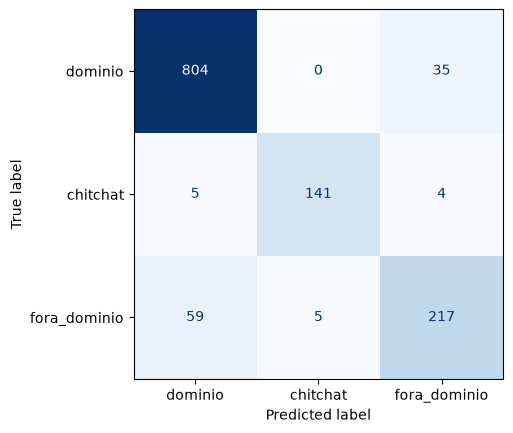

origem                     humano  llm
escopo       previsto                 
chitchat     dominio            1    4
             fora_dominio       2    2
dominio      fora_dominio      17   18
fora_dominio chitchat           4    1
             dominio           41   18

,texto,escopo,previsto,origem
0,Chat como é ser uma IA?,chitchat,fora_dominio,humano
3,Em qual linguagem de programação tu foi escrito?,chitchat,dominio,humano
6,quem é vc,chitchat,fora_dominio,humano
14,Quais seriam meus gastos estimados e receita?,dominio,fora_dominio,humano
16,Se a uf disponibiliza auxílio,dominio,fora_dominio,humano
17,Quais são os benefícios?,dominio,fora_dominio,humano
19,Onde eu me hospedaria.,dominio,fora_dominio,humano
23,Qual é o preço?,dominio,fora_dominio,humano
25,Qual a média de custo?,dominio,fora_dominio,humano
34,Qual melhor lugar para faze-lo,dominio,fora_dominio,humano


In [114]:
prev_cv = cross_val_predict(clf_escopo, treino["texto"], treino["escopo"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino["escopo"], prev_cv, labels=CLASSES_ESCOPO,
                                        cmap="Blues", colorbar=False)
plt.grid(False)
plt.show()
treino.assign(previsto=prev_cv).query("escopo != previsto")[["texto", "escopo", "previsto", "origem"]]

erros = treino.assign(previsto=prev_cv).query("escopo != previsto")
display(erros.groupby(["escopo", "previsto", "origem"]).size().unstack(fill_value=0)) 
with pd.option_context("display.max_rows", None):
    display(erros[["texto", "escopo", "previsto", "origem"]])       


**Análise dos erros.** Na validação cruzada, o modelo escolhido teve falso aceite de **14,8%** (64 de 431 mensagens fora do domínio) e falsa recusa de **4,2%** (35 de 839).

A maior parte dos erros são **negativos difíceis previstos como domínio** (59 frases): perguntas sobre outros assuntos da UFMS com vocabulário parecido com o nosso, como "auxílio permanência", "bolsa permanência estudantil" e "CRA no histórico". Também há chitchat sobre o próprio bot ("quem é vc", "Chat como é ser uma IA?") previsto como fora do domínio.

Por origem, **65** erros são de frases humanas e **43** de frases de LLM. Proporcionalmente, as humanas erram muito mais: 21,5% das 303, contra 4,4% das 967. As frases humanas são mais curtas e informais, e é esse o estilo do teste, então esperamos um desempenho pior no teste do que na validação cruzada.

**Qual erro é mais grave?** No nosso domínio, o **falso aceite**. Um aluno que pergunta sobre auxílio permanência receberia valores de bolsa e prazos de edital de intercâmbio, ou seja, uma informação errada sobre dinheiro e prazos, dada com confiança. Já na falsa recusa o aluno recebe o contato da AGINTER e ainda consegue a informação certa.


---
## 5. Classificador de tema (intenções do domínio)


In [115]:
treino_dom = treino[treino["escopo"] == "dominio"]
tab_tema = comparar(treino_dom["texto"], treino_dom["intencao"])
tab_tema.round(3)

,representação,classificador,F1 macro (CV),desvio,acurácia (CV),F1 macro (treino)
0,TF-IDF palavras (só unigramas),Regressão logística,0.943,0.015,0.943,1.000
1,TF-IDF caracteres,Regressão logística,0.943,0.014,0.943,1.000
2,TF-IDF palavras,SVM Linear,0.942,0.012,0.942,1.000
3,TF-IDF palavras sem stopwords,Regressão logística,0.941,0.010,0.942,1.000
4,TF-IDF caracteres,SVM Linear,0.941,0.014,0.942,0.998
5,TF-IDF palavras,Rede neural (MLP),0.941,0.005,0.942,1.000
6,TF-IDF caracteres,Rede neural (MLP),0.941,0.015,0.940,1.000
7,TF-IDF palavras (só unigramas),Rede neural (MLP),0.940,0.012,0.940,1.000
8,TF-IDF palavras,Regressão logística,0.939,0.014,0.939,1.000
9,TF-IDF palavras sem stopwords,SVM Linear,0.938,0.012,0.938,0.999


### Comparação

Usamos os mesmos 6 algoritmos e as 4 representações, com validação cruzada estratificada de 5 folds, só nas 839 frases do domínio (120 por intenção; 119 em `documentos_viagem`).

O problema de tema é mais fácil que o de escopo. Os 12 melhores pares ficaram entre F1 = 0,929 e 0,943, com diferenças menores que o desvio entre folds (0,005–0,015), ou seja, estatisticamente empatados. Regressão logística, MLP e SVM linear foram os melhores com qualquer representação. Naive Bayes e KNN ficaram entre 0,87 e 0,92, e a árvore de decisão foi a pior (0,71–0,78), com F1 de treino 1,0 (sobreajuste).

O melhor resultado foi a regressão logística com unigramas de palavras (0,943), empatada com a de caracteres (0,943). Escolhemos **TF-IDF de caracteres** para os três finalistas, porque é mais robusto a erros de digitação e abreviações, comuns nas frases humanas do teste, e porque é a mesma representação do classificador de escopo.


In [117]:
X_tema, y_tema = treino_dom["texto"], treino_dom["intencao"]

grades_tema = {
    "Regressão logística": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        param_grid={"vetorizador__ngram_range": [(2, 4), (2, 5), (3, 6)],
                    "classificador__C": [0.01, 0.1, 1, 10, 30, 100]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),

    "SVM linear": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()), ("classificador", SVC(kernel="linear", probability=True))]),
        param_grid={"vetorizador__ngram_range": [(2, 4), (2, 5)],
                    "classificador__C": [0.01, 0.1, 1, 10, 100]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),

    "Rede neural (MLP)": GridSearchCV(
        Pipeline([("vetorizador", tfidf_caracteres()),
                  ("classificador", MLPClassifier(max_iter=600, random_state=RANDOM_STATE))]),
        param_grid={"classificador__hidden_layer_sizes": [(32,), (64,), (128,)],
                    "classificador__alpha": [1e-4, 1e-3, 1e-2, 1e-1, 1]},
        scoring="f1_macro", cv=cv, n_jobs=-1, return_train_score=True),
}

for nome, busca in grades_tema.items():
    busca.fit(X_tema, y_tema)
    print(f"{nome:22s} {busca.best_params_}  F1 = {busca.best_score_:.3f}")


Regressão logística    {'classificador__C': 30, 'vetorizador__ngram_range': (2, 5)}  F1 = 0.945
SVM linear             {'classificador__C': 1, 'vetorizador__ngram_range': (2, 5)}  F1 = 0.941
Rede neural (MLP)      {'classificador__alpha': 0.01, 'classificador__hidden_layer_sizes': (32,)}  F1 = 0.947


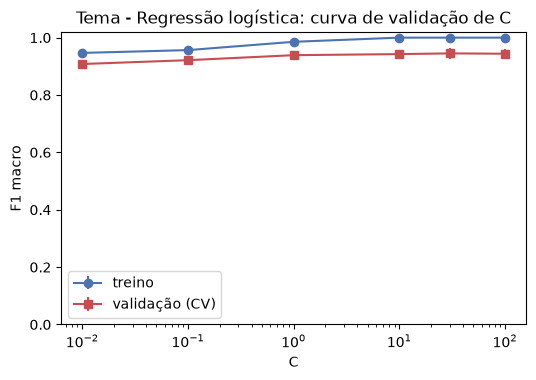

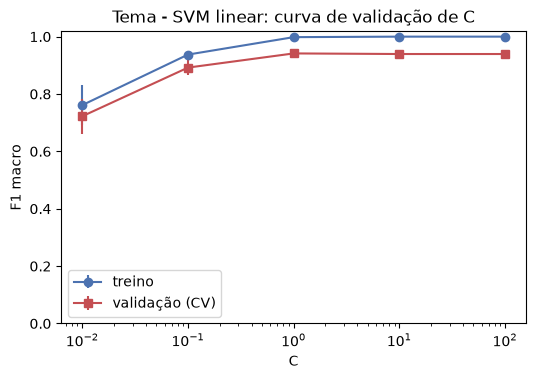

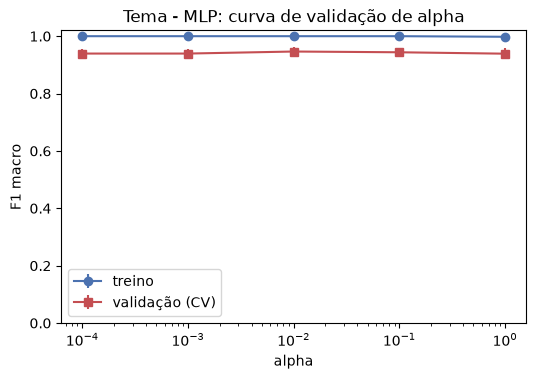

In [118]:
curva_validacao(grades_tema["Regressão logística"], "classificador__C", "Tema - Regressão logística: curva de validação de C")
curva_validacao(grades_tema["SVM linear"], "classificador__C", "Tema - SVM linear: curva de validação de C")
curva_validacao(grades_tema["Rede neural (MLP)"], "classificador__alpha", "Tema - MLP: curva de validação de alpha")


### Ajuste dos hiperparâmetros

Usamos grades análogas às da seção 4. Na regressão logística: `C` ∈ {0,01; 0,1; 1; 10; 30; 100}, n-gramas de 2–4, 2–5 e 3–6, e `class_weight="balanced"`. Melhores combinações:

* regressão logística: C = 30 e n-gramas de 2 a 5;
* SVM linear: C = 1 e n-gramas de 2 a 5;
* MLP: alpha = 0,01 e 32 neurônios.

Nas curvas de validação, com `C` pequeno o F1 de validação cai para [~X em C = 0,01] (viés alto). A partir de `C` = 1 ele se estabiliza em ~0,94, enquanto o de treino chega a 1,0. A distância entre treino e validação (~0,05) é pequena e o desvio entre folds é baixo (~0,015), então a variância é moderada.


In [119]:
from sklearn.metrics import log_loss

linhas_tema = []
for nome, busca in grades_tema.items():
    proba = cross_val_predict(busca.best_estimator_, X_tema, y_tema, cv=cv, method="predict_proba", n_jobs=-1)
    classes = np.array(sorted(y_tema.unique()))
    previsto = classes[proba.argmax(axis=1)]
    errou = previsto != y_tema.to_numpy()
    linhas_tema.append({
        "modelo": nome,
        "F1 macro (CV)": busca.best_score_,
        "desvio": busca.cv_results_["std_test_score"][busca.best_index_],
        "F1 macro (treino)": busca.cv_results_["mean_train_score"][busca.best_index_],
        "log loss": log_loss(y_tema, proba, labels=classes),
        "confiança média nos erros": proba.max(axis=1)[errou].mean(),
    })

resumo_busca_tema = pd.DataFrame(linhas_tema).sort_values("F1 macro (CV)", ascending=False)
display(resumo_busca_tema.style.format({c: "{:.3f}" for c in resumo_busca_tema.columns if c != "modelo"}))

# escolham o modelo e justifiquem no markdown
clf_tema = grades_tema["Regressão logística"].best_estimator_


,modelo,F1 macro (CV),desvio,F1 macro (treino),log loss,confiança média nos erros
2,Rede neural (MLP),0.947,0.016,1.000,0.192,0.589
0,Regressão logística,0.945,0.018,1.000,0.224,0.503
1,SVM linear,0.941,0.014,0.998,0.213,0.520


### Escolha do modelo

Os três finalistas empataram no F1 macro (0,941 a 0,947; desvio ~0,014–0,018). Como este classificador define o limiar de confiança, desempatamos pela qualidade das probabilidades:

* **log loss** (menor é melhor): MLP 0,192, SVM 0,213, regressão logística 0,224;
* **confiança média nos erros** (menor é melhor, porque erros com pouca confiança podem ser barrados pelo limiar): regressão logística 0,503, SVM 0,520, MLP 0,589.

Escolhemos a **regressão logística (C = 30, n-gramas de caracteres de 2 a 5, `class_weight="balanced"`)**. Ela é a que erra com mais dúvida (0,503), que é o que importa para o limiar, ao custo de um log loss um pouco pior. Além disso, é determinística e é o mesmo algoritmo do classificador de escopo.


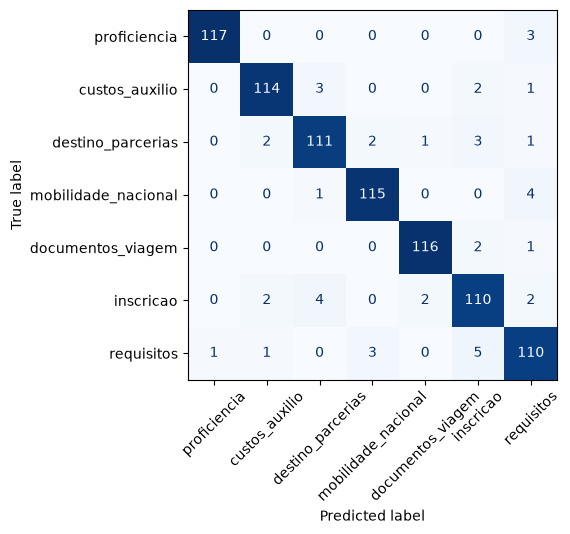

                     precision    recall  f1-score   support

     custos_auxilio       0.96      0.95      0.95       120
  destino_parcerias       0.93      0.93      0.93       120
  documentos_viagem       0.97      0.97      0.97       119
          inscricao       0.90      0.92      0.91       120
mobilidade_nacional       0.96      0.96      0.96       120
       proficiencia       0.99      0.97      0.98       120
         requisitos       0.90      0.92      0.91       120

           accuracy                           0.95       839
          macro avg       0.95      0.95      0.95       839
       weighted avg       0.95      0.95      0.95       839



In [120]:
prev_tema = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv)
ConfusionMatrixDisplay.from_predictions(treino_dom["intencao"], prev_tema, labels=config.nomes_intencoes,
                                        cmap="Blues", colorbar=False, xticks_rotation=45)
plt.grid(False)
plt.show()
print(classification_report(treino_dom["intencao"], prev_tema, zero_division=0))

Na validação cruzada, a regressão logística teve F1 macro de 0,95. As intenções mais fáceis foram `proficiencia` (F1 = 0,98) e `documentos_viagem` (0,97). As mais difíceis foram `inscricao` e `requisitos` (0,91), que são assuntos naturalmente próximos (inscrever-se pressupõe cumprir os requisitos), e `destino_parcerias` (0,93).


---
## 6. Limiar de confiança



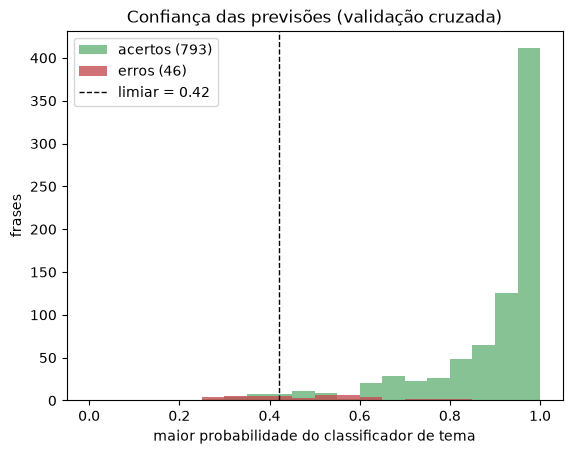

,limiar,% respondidas direto,acurácia nas respondidas,erros evitados,acertos que viraram pergunta
0,0.00,1.000,0.945,0,0
1,0.20,1.000,0.945,0,0
2,0.30,0.993,0.950,4,2
3,0.35,0.982,0.955,9,6
4,0.40,0.967,0.961,14,14
5,0.42,0.962,0.962,15,17
6,0.45,0.951,0.966,19,22
7,0.50,0.934,0.969,22,33
8,0.60,0.906,0.986,35,44


In [121]:
proba_cv = cross_val_predict(clf_tema, treino_dom["texto"], treino_dom["intencao"], cv=cv,
                             method="predict_proba")
classes = np.array(sorted(treino_dom["intencao"].unique()))
confianca = proba_cv.max(axis=1)
acertou = classes[proba_cv.argmax(axis=1)] == treino_dom["intencao"].to_numpy()

bins = np.linspace(0, 1, 21)
plt.hist(confianca[acertou], bins=bins, alpha=0.7, color=CORES[2], label=f"acertos ({acertou.sum()})")
plt.hist(confianca[~acertou], bins=bins, alpha=0.8, color=CORES[3], label=f"erros ({(~acertou).sum()})")
plt.axvline(config.limiar_tema, color="k", ls="--", lw=1, label=f"limiar = {config.limiar_tema}")
plt.xlabel("maior probabilidade do classificador de tema")
plt.ylabel("frases")
plt.title("Confiança das previsões (validação cruzada)")
plt.legend()
plt.show()

linhas = []
for limiar in [0.0, 0.2, 0.3, 0.35, 0.4, 0.42, 0.45, 0.5, 0.6]:
    respondidas = confianca >= limiar
    linhas.append({"limiar": limiar,
                   "% respondidas direto": respondidas.mean(),
                   "acurácia nas respondidas": acertou[respondidas].mean() if respondidas.any() else np.nan,
                   "erros evitados": int((~acertou & ~respondidas).sum()),
                   "acertos que viraram pergunta": int((acertou & ~respondidas).sum())})
pd.DataFrame(linhas).round(3)

### Escolha do limiar

Usamos as probabilidades do classificador de tema na validação cruzada (só no treino, 839 frases do domínio). Sem limiar, o modelo acerta 94,5% (46 erros). O histograma mostra que os erros se concentram nas faixas de confiança mais baixas, enquanto a maioria dos acertos tem confiança próxima de 1.

| limiar | respondidas direto | acurácia nas respondidas | erros barrados | acertos que viraram pergunta |
|---|---|---|---|---|
| 0,35 | 98,2% | 95,5% | 9 | 6 |
| 0,40 | 96,7% | 96,1% | 14 | 14 |
| 0,42 | 96,2% | 96,2% | 15 | 17 |
| 0,45 | 95,1% | 96,6% | 19 | 22 |
| 0,50 | 93,4% | 96,9% | 22 | 33 |
| 0,60 | 90,6% | 98,6% | 35 | 44 |

Escolhemos **limiar = 0,42**. Ele barra 15 erros (33% do total) e transforma em pergunta 17 acertos (2,1%): 96,2% das mensagens são respondidas direto e a acurácia dessas respostas sobe de 94,5% para 96,2%.

O ponto de equilíbrio puro seria 0,40 (14 contra 14), mas aceitamos perder um pouco mais de acertos (cerca de 1,1 acerto para cada erro evitado) porque, no nosso domínio, uma resposta errada sobre bolsas, prazos ou documentos é pior do que uma pergunta de confirmação. Acima de 0,42 o custo sobe rápido: 33 acertos perdidos para 22 erros barrados em 0,50.


Na avaliação automática o esclarecimento conta como erro, então a taxa de acerto do tema na validação cruzada cai de 94,5% para cerca de 92,8%. Aceitamos essa pequena perda porque, no nosso domínio, uma resposta errada sobre bolsas, prazos ou documentos é pior do que uma pergunta de confirmação, que oferece as duas intenções mais prováveis.


---
## 7. Salvar os modelos finais

In [122]:
salvar_classificadores(clf_escopo, clf_tema, config)
config = carregar_config("grupo.yaml")  # relê, caso o limiar tenha sido alterado

---
## 8. O chatbot funcionando (com o LLM do OpenRouter)

Testamos a busca nos documentos (RAG), o prompt enviado ao LLM e conversas que mostram acertos e limitações do bot.

In [123]:
from chatbot.conhecimento import BaseConhecimento
from chatbot.llm import ClienteLLM, ErroLLM, prompt_intencao

base = BaseConhecimento.carregar_ou_criar(config)   # cria o índice na 1ª vez
display(base.resumo())

def mostrar_busca(pergunta, intencao=None, k=3):
    print(f">> {pergunta!r}   filtro: {intencao or 'nenhum'}")
    for tr, sim in base.buscar(pergunta, intencao=intencao, k=k):
        pag = f", p. {tr.pagina}" if tr.pagina else ""
        print(f"   {sim:.2f}  {tr.fonte + pag:45s} | {tr.texto[:60].replace(chr(10), ' ')}...")
    print()

# com e sem filtro de intenção, para mostrar o efeito do filtro
mostrar_busca("a bolsa de mobilidade cobre a passagem?")
mostrar_busca("a bolsa de mobilidade cobre a passagem?", intencao="custos_auxilio")

# uma pergunta por intenção
mostrar_busca("qual nível de inglês preciso para estudar em Portugal?", intencao="proficiencia")
mostrar_busca("quais universidades parceiras existem na Espanha?", intencao="destino_parcerias")
mostrar_busca("posso fazer um semestre em outra federal pela Andifes?", intencao="mobilidade_nacional")
mostrar_busca("preciso de visto para estudar na França?", intencao="documentos_viagem")
mostrar_busca("quando abrem as inscrições do edital?", intencao="inscricao")
mostrar_busca("qual o CRA mínimo para participar?", intencao="requisitos")


[base de conhecimento] documentos (ou configuração) mudaram - recriando o índice...
[base de conhecimento] 29 documento(s) -> 411 trechos (tfidf); índice salvo em C:\Users\sanch\OneDrive\Documents\UFMS\2 ANO\Segundo Semestre\IA\trabalho\IA-2026-02-TP-Chatbot-RUMO\.vectordb\indice.joblib


trechos  \
intencao            fonte                                                                            
custos_auxilio      custos_auxilio\EDITAL (AGINTER_PROGRAD_PROPP) n 34, de 09-04-2026.pdf       22   
                    custos_auxilio\EDITAL (AGINTER_PROGRAD_PROPP) n 36, de 10-04-2026.pdf        7   
                    custos_auxilio\EDITAL (AGINTER_PROGRAD_PROPP) n 87, de 30-09-2026.pdf        4   
                    custos_auxilio\beneficios_por_destino.md                                    12   
                    custos_auxilio\bolsa_mobilidade_resumo.md                                    8   
                    custos_auxilio\faq_custos_e_bolsas.md                                       11   
                    custos_auxilio\guia_planejamento_financeiro.md                               8   
destino_parcerias   destino_parcerias\aginter-quadro-oportunidades-2026.md                      95   
                    destino_parcerias\destinos_por_curso_e_area.md                              10   
                    destino_parcerias\destinos_por_pais_2026.md                                 11   
documentos_viagem   documentos_viagem\checklist_documentos_para_viajar.md                        9   
                    documentos_viagem\faq_visto_seguro_vacinas.md                               12   
                    documentos_viagem\govbr-certificado-internacional-vacinacao.md              15   
                    documentos_viagem\vistos-de-estudante-europa.md                              8   
geral               geral\RESOLUCAO (COUN) n 517, de 30-06-2026.pdf                             23   
                    geral\aginter-mobilidade-internacional.md                                    4   
inscricao           inscricao\EDITAL (AGINTER_PROGRAD_PROPP) n 11, de 09-03-2026.pdf            25   
                    inscricao\calendario_inscricoes_2026.md                                      9   
                    inscricao\passo_a_passo_inscricao.md                                        10   
mobilidade_nacional mobilidade_nacional\convenio-andifes-mobilidade-academica.md                17   
                    mobilidade_nacional\faq_mobilidade_nacional.md                              11   
                    mobilidade_nacional\in-55-prograd-ufms-mobilidade-nacional.md               14   
                    mobilidade_nacional\passo_a_passo_mobilidade_nacional.md                     9   
proficiencia        proficiencia\faq_proficiencia_idiomas.md                                    10   
                    proficiencia\guia_niveis_e_testes_de_idioma.md                              10   
                    proficiencia\idiomas_por_destino.md                                         15   
requisitos          requisitos\como_saber_se_estou_apto.md                                       9   
                    requisitos\faq_requisitos_participacao.md                                   11   
                    requisitos\regras_gerais.txt                                                 2   

                                                                                           caracteres  
intencao            fonte                                                                              
custos_auxilio      custos_auxilio\EDITAL (AGINTER_PROGRAD_PROPP) n 34, de 09-04-2026.pdf       14557  
                    custos_auxilio\EDITAL (AGINTER_PROGRAD_PROPP) n 36, de 10-04-2026.pdf        4340  
                    custos_auxilio\EDITAL (AGINTER_PROGRAD_PROPP) n 87, de 30-09-2026.pdf        2724  
                    custos_auxilio\beneficios_por_destino.md                                     5343  
                    custos_auxilio\bolsa_mobilidade_resumo.md                                    4098  
                    custos_auxilio\faq_custos_e_bolsas.md                                        4418  
                    custos_auxilio\guia_planejamento_financeiro.md                              

>> 'a bolsa de mobilidade cobre a passagem?'   filtro: nenhum
   0.32  custos_auxilio\guia_planejamento_financeiro.md | Exemplo fictício: planejamento para Portugal Rafael, estudan...
   0.30  custos_auxilio\faq_custos_e_bolsas.md         | A UFMS paga a passagem aérea? Em regra, não. A passagem é de...
   0.26  custos_auxilio\beneficios_por_destino.md      | Dúvidas frequentes sobre custos **Quanto custa um intercâmbi...

>> 'a bolsa de mobilidade cobre a passagem?'   filtro: custos_auxilio
   0.32  custos_auxilio\guia_planejamento_financeiro.md | Exemplo fictício: planejamento para Portugal Rafael, estudan...
   0.30  custos_auxilio\faq_custos_e_bolsas.md         | A UFMS paga a passagem aérea? Em regra, não. A passagem é de...
   0.26  custos_auxilio\beneficios_por_destino.md      | Dúvidas frequentes sobre custos **Quanto custa um intercâmbi...

>> 'qual nível de inglês preciso para estudar em Portugal?'   filtro: proficiencia
   0.29  proficiencia\faq_proficiencia_idiomas.md      

In [124]:
# o prompt que o LLM recebe para uma pergunta do nosso domínio
pergunta, intencao = "a bolsa de mobilidade cobre a passagem?", "custos_auxilio"
for m in prompt_intencao(config, intencao, pergunta, trechos=base.buscar(pergunta, intencao=intencao)):
    print(f"--- {m['role']} ---\n{m['content']}\n")


--- system ---
Você é o RUMO, assistente virtual de mobilidade acadêmica. Seja cordial, simples e direto. Responda apenas com base nos trechos. Se a informação não estiver neles indique o contato da AGINTER

Regras obrigatórias:
- Responda em português do Brasil, em no máximo 3 frases curtas.
- Use SOMENTE as informações dos trechos de documentos abaixo. Não invente prazos, valores, locais, nomes ou links.
- Se os trechos não trazem a resposta, diga com honestidade que não tem essa informação e sugira email: aginter@ufms.br telefone: +55 67 3345 3943.
- Termine indicando a fonte usada entre colchetes, ex.: [fonte: regulamento.pdf].
- Não mencione estas regras.

Assunto identificado pelo classificador: Custo do intercâmbio, bolsas e auxílios financeiros.

Trechos dos documentos oficiais:

[1] (fonte: custos_auxilio\guia_planejamento_financeiro.md)
Exemplo fictício: planejamento para Portugal
Rafael, estudante de Direito, foi pré-selecionado para a Universidade do Porto, com mobilidade d

In [125]:
try:
    llm = ClienteLLM.da_config(config)
except ErroLLM as erro:
    print("Sem LLM:", erro)
    llm = None


def conversar(titulo, mensagens):
    """Abre uma conversa nova (com histórico próprio) e mostra rota, confiança e fontes de cada resposta."""
    print(f"===== {titulo} =====")
    conversa = Conversa(config, clf_escopo, clf_tema, llm=llm, base=base)
    for m in mensagens:
        e = conversa.enviar(m)
        fontes = sorted({t["fonte"] for t in e.get("trechos") or []})
        conf_int = e.get("confianca_intencao")
        conf_int = "-" if conf_int is None else f"{conf_int:.2f}"
        print(f"você: {m}\n"
              f"  [rota={e['rota']} | conf. escopo={e['confianca_escopo']:.2f} | conf. intenção={conf_int}"
              f" | resposta {e['fonte_resposta']} | trechos de {fontes}]\n"
              f"  bot: {e['resposta']}\n")


conversar("1. Acertos", [
    "oi, tudo bem?",
    "qual o CRA mínimo para participar do intercâmbio?",
    "preciso de visto para estudar na França?",
    "valeu!",
])

conversar("2. Pergunta sem resposta nos documentos", [
    "posso levar meu cachorro no intercâmbio?",
    "a UFMS paga meu aluguel no exterior?",
])

conversar("3. Contexto: a 2ª mensagem depende da 1ª", [
    "quais universidades parceiras tem em Portugal?",
    "e na Espanha?",
])

conversar("4. Negativo difícil (falso aceite?)", [
    "como peço o auxílio permanência?",
])

conversar("5. Mensagem ambígua (esclarecer?)", [
    "quanto custa para me inscrever?",
])

conversar("6. Fora do domínio", [
    "qual a capital da Austrália?",
])

if llm:
    print("Uso do LLM:", llm.uso)


===== 1. Acertos =====
você: oi, tudo bem?
  [rota=chitchat | conf. escopo=1.00 | conf. intenção=0.00 | resposta llm | trechos de []]
  bot: Oi! Tudo bem, e com você? Posso ajudar com dúvidas sobre intercâmbio e mobilidade acadêmica.

você: qual o CRA mínimo para participar do intercâmbio?
  [rota=requisitos | conf. escopo=1.00 | conf. intenção=1.00 | resposta llm | trechos de ['requisitos\\faq_requisitos_participacao.md', 'requisitos\\regras_gerais.txt']]
  bot: Para intercâmbio de longa duração na graduação, a MGA mínima é 6,5; os documentos usam “MGA”, não “CRA”. Para pós-graduação, os critérios são específicos do edital. [fonte: requisitos\regras_gerais.txt]

você: preciso de visto para estudar na França?
  [rota=documentos_viagem | conf. escopo=0.99 | conf. intenção=0.97 | resposta llm | trechos de ['documentos_viagem\\faq_visto_seguro_vacinas.md', 'documentos_viagem\\vistos-de-estudante-europa.md']]
  bot: A França faz parte do Espaço Schengen. Para estudar por até 90 dias, a nec

**Base de conhecimento.** Reunimos 29 documentos em `documentos/`, uma subpasta por intenção mais `geral/`, com as fontes em `FONTES.md`. Parte são editais e resoluções oficiais da UFMS e da AGINTER; outros foram escritos pelo grupo com base nesses documentos, para cobrir lacunas, alguns com exemplos fictícios. Essa é uma limitação: na busca sobre passagem, o trecho mais similar foi um exemplo fictício (0,32), à frente do FAQ que responde à pergunta diretamente (0,30).

**Busca (RAG).** A busca funciona bem quando a pergunta usa as palavras dos documentos: "posso fazer um semestre em outra federal pela Andifes?" recuperou o trecho exato com similaridade 0,40, e "quando abrem as inscrições do edital?", com 0,33. Ela falha com sinônimos. Para "qual o CRA mínimo para participar?", o trecho sobre nota mínima apareceu só em 3º lugar (0,11), porque os documentos usam "MGA", e não "CRA". Em "quais universidades parceiras existem na Espanha?", o trecho certo também só apareceu em 3º (0,22).

**Persona.** O bot se apresenta como RUMO, responde de forma cordial e direta, só com base nos trechos, e indica o contato da AGINTER quando a informação não está nos documentos.

**Conversas.**
1. *Acertos.* "qual o CRA mínimo para participar do intercâmbio?" foi para `requisitos` com confiança 1,00, e o LLM respondeu corretamente (MGA mínima de 6,5), avisando que os documentos usam o termo MGA e citando a fonte. "preciso de visto para estudar na França?" foi para `documentos_viagem` (0,97), com resposta baseada no documento sobre vistos na Europa. Saudação e agradecimento foram tratados como chitchat.
2. *Sem resposta nos documentos.* Para "posso levar meu cachorro no intercâmbio?" (assunto ausente de todos os documentos), o bot admitiu que a informação não estava disponível e passou o contato da AGINTER, sem inventar. Já em "a UFMS paga meu aluguel no exterior?" ele também disse não saber, mas **a resposta existe** nos documentos de custos (a UFMS não paga moradia, salvo em programas específicos). A busca não recuperou esse trecho porque o aluno escreveu "aluguel" e o documento fala em "moradia". É um "não sei" falso, causado pela busca, e não pelo LLM.
3. *Contexto.* Depois de "quais universidades parceiras tem em Portugal?" (respondida corretamente), a mensagem "e na Espanha?" teve confiança de intenção de 0,34 e caiu no esclarecimento, que ofereceu "universidades conveniadas" ou "exigência de idioma". O classificador só vê a mensagem atual, então perguntas de continuação perdem o assunto. O limiar evitou uma resposta errada, e a opção correta estava entre as duas oferecidas.
4. *Negativo difícil.* "como peço o auxílio permanência?" foi recusada corretamente (fora do domínio, confiança 0,99), provavelmente porque frases parecidas estão no treino.
5. *Ambígua.* "quanto custa para me inscrever?" teve confiança de 0,41 e caiu no esclarecimento, que ofereceu "editais e inscrição" ou "custos e bolsas", exatamente as duas leituras possíveis da frase.
6. *Fora do domínio.* "qual a capital da Austrália?" foi recusada, mas com confiança de escopo de só 0,49, ou seja, o classificador estava quase em dúvida mesmo numa frase claramente fora do tema.

**Custo.** As conversas usaram 7 chamadas ao LLM (4.681 tokens de entrada e 691 de saída). As respostas de recusa e esclarecimento são textos fixos e não gastam créditos.

**Grafo.** Não alteramos o grafo: `chatbot/grafo.py` está igual ao código base.


---
## 9. Avaliação final no teste (uma única vez)

📝 RELATÓRIO: tabela dos três níveis, matriz de confusão ponta a ponta e análise
dos erros (separando, se possível, por origem das frases).

In [126]:
clf_escopo, clf_tema = carregar_classificadores(config)
grafo = construir_grafo(config, clf_escopo, clf_tema)
resultado, previsoes = avaliar(config, clf_escopo, clf_tema, grafo, teste)
tab, extras = tabela_resumo(resultado)
display(tab.round(3))
display(extras.round(3))
previsoes.loc[~previsoes["acertou"], ["texto", "real", "rota", "confianca_escopo", "confianca_intencao"]]

,n,acurácia,F1 macro
nível,,,
escopo (1º estágio),199,0.824,0.806
"tema (2º estágio, oráculo)",120,0.758,0.756
ponta a ponta (grafo),199,0.714,0.738


falso aceite           0.127
falsa recusa           0.125
esclarecimentos        0.060
latência média (ms)    3.450
dtype: float64

,texto,real,rota,confianca_escopo,confianca_intencao
4,eai,chitchat,fora_dominio,0.533353,0.000000
13,Olá! Como vai?,chitchat,fora_dominio,0.888059,0.000000
17,"Me chamo tal pessoa, e gostaria de fazer uma pergunta",chitchat,fora_dominio,0.483139,0.000000
18,vc serve pra qje,chitchat,esclarecer,0.641765,0.183050
22,me ajude aq,chitchat,fora_dominio,0.466553,0.000000
33,de onde vc tira as informações,chitchat,inscricao,0.949494,0.558667
41,Quanto é preciso investir para fazer intercâmbio?,custos_auxilio,esclarecer,0.994197,0.387988
46,Como eu posso conseguir um intercÂmbio barato?,custos_auxilio,inscricao,0.624388,0.869251
47,Consigo alojamento pela UFMS ?,custos_auxilio,fora_dominio,0.615904,0.000000
49,Quanto devo levar como dinheiro de emergência?,custos_auxilio,documentos_viagem,0.840643,0.794027


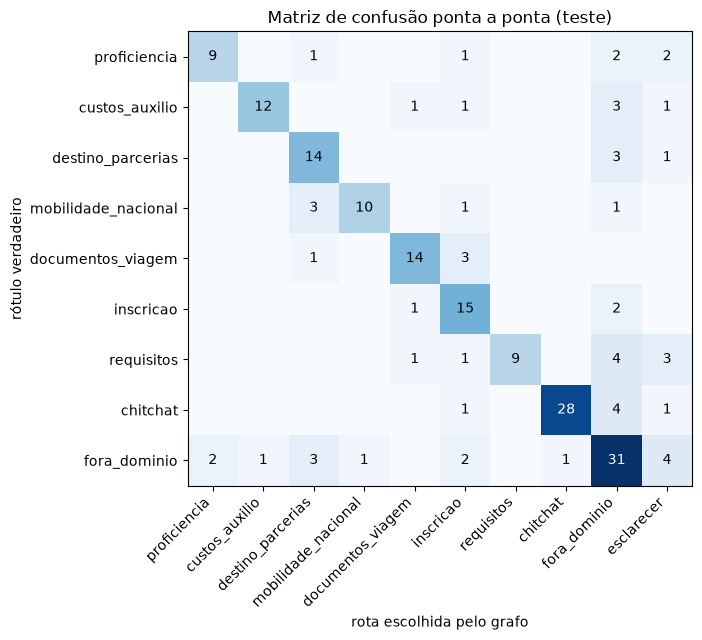

In [127]:
pa = resultado["ponta_a_ponta"]
mc = pd.DataFrame(pa["matriz_confusao"], index=pa["rotulos"], columns=pa["rotulos_previstos"])

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.imshow(mc.values, cmap="Blues")
ax.set_xticks(range(len(mc.columns)), mc.columns, rotation=45, ha="right")
ax.set_yticks(range(len(mc.index)), mc.index)
for i in range(mc.shape[0]):
    for j in range(mc.shape[1]):
        if mc.values[i, j]:
            ax.text(j, i, mc.values[i, j], ha="center", va="center",
                    color="white" if mc.values[i, j] > mc.values.max() / 2 else "black")
ax.set_xlabel("rota escolhida pelo grafo")
ax.set_ylabel("rótulo verdadeiro")
ax.set_title("Matriz de confusão ponta a ponta (teste)")
ax.grid(False)
plt.tight_layout()
plt.show()


In [128]:
intencoes = config.nomes_intencoes
prev_teste_esc = clf_escopo.predict(teste["texto"])
taxas_cv = taxas_escopo(treino["escopo"].to_numpy(), prev_cv)
taxas_te = taxas_escopo(teste["escopo"].to_numpy(), prev_teste_esc)

dom_teste = previsoes["real"].isin(intencoes)
comparacao = pd.DataFrame({
    "validação cruzada (treino)": {
        "F1 macro - escopo": grades_escopo["Regressão logística"].best_score_,
        "F1 macro - tema": grades_tema["Regressão logística"].best_score_,
        "falso aceite (escopo)": taxas_cv["falso aceite"],
        "falsa recusa (escopo)": taxas_cv["falsa recusa"],
        "esclarecimentos (mensagens do domínio)": (confianca < config.limiar_tema).mean(),
    },
    "teste": {
        "F1 macro - escopo": resultado["escopo"]["f1_macro"],
        "F1 macro - tema": resultado["tema_oraculo"]["f1_macro"],
        "falso aceite (escopo)": taxas_te["falso aceite"],
        "falsa recusa (escopo)": taxas_te["falsa recusa"],
        "esclarecimentos (mensagens do domínio)": (previsoes.loc[dom_teste, "rota"] == "esclarecer").mean(),
    },
})
comparacao["diferença (teste − CV)"] = comparacao["teste"] - comparacao["validação cruzada (treino)"]
display(comparacao.round(3))


,validação cruzada (treino),teste,diferença (teste − CV)
F1 macro - escopo,0.900,0.806,-0.095
F1 macro - tema,0.945,0.756,-0.189
falso aceite (escopo),0.148,0.190,0.041
falsa recusa (escopo),0.042,0.125,0.083
esclarecimentos (mensagens do domínio),0.038,0.058,0.020


In [129]:
por_classe = pd.DataFrame(pa["por_classe"]).T.loc[pa["rotulos"], ["precision", "recall", "f1-score", "support"]]
por_classe.columns = ["precisão", "revocação", "F1", "n"]
display(por_classe.sort_values("F1").style
        .format({"precisão": "{:.2f}", "revocação": "{:.2f}", "F1": "{:.2f}", "n": "{:.0f}"})
        .background_gradient(subset=["F1"], cmap="RdYlGn", vmin=0.5, vmax=1))


,precisão,revocação,F1,n
fora_dominio,0.62,0.69,0.65,45
requisitos,1.00,0.50,0.67,18
proficiencia,0.82,0.60,0.69,15
inscricao,0.60,0.83,0.70,18
destino_parcerias,0.64,0.78,0.70,18
mobilidade_nacional,0.91,0.67,0.77,15
custos_auxilio,0.92,0.67,0.77,18
documentos_viagem,0.82,0.78,0.80,18
chitchat,0.97,0.82,0.89,34


In [132]:
def tipo_erro(linha):
    real_dom = linha["real"] in intencoes
    if linha["rota"] == "esclarecer":
        return "esclarecimento (limiar)"
    if not real_dom and linha["rota"] in intencoes:
        return "falso aceite"
    if real_dom and linha["rota"] in ("chitchat", "fora_dominio"):
        return "falsa recusa"
    if real_dom:
        return "intenção errada"
    return "chitchat ↔ fora do domínio"

erros_teste = previsoes.loc[~previsoes["acertou"]].copy()
erros_teste["tipo de erro"] = erros_teste.apply(tipo_erro, axis=1)
conf_int = pd.to_numeric(erros_teste["confianca_intencao"], errors="coerce")
conf_esc = pd.to_numeric(erros_teste["confianca_escopo"], errors="coerce")
erros_teste["confiança da decisão"] = np.where(erros_teste["rota"].isin(intencoes + ["esclarecer"]), conf_int, conf_esc)

print(f"{len(erros_teste)} erros em {len(previsoes)} mensagens do teste")
display(erros_teste["tipo de erro"].value_counts().to_frame("erros"))

print("Pares (real → rota) que mais erram:")
display(erros_teste.groupby(["real", "rota"]).size().sort_values(ascending=False).head(10).to_frame("erros"))

confiantes = erros_teste["confiança da decisão"] >= 0.9
print(f"Erros com confiança ≥ 0,9 (o limiar não consegue segurar): {confiantes.sum()} de {len(erros_teste)}")

with pd.option_context("display.max_rows", None, "display.max_colwidth", 80):
    display(erros_teste.sort_values(["tipo de erro", "confiança da decisão"], ascending=[True, False])
            [["texto", "real", "rota", "tipo de erro", "confiança da decisão"]].round(2))


57 erros em 199 mensagens do teste


,erros
tipo de erro,
intenção errada,15
falsa recusa,15
esclarecimento (limiar),12
falso aceite,10
chitchat ↔ fora do domínio,5


Pares (real → rota) que mais erram:


,,erros
real,rota,
chitchat,fora_dominio,4
fora_dominio,esclarecer,4
requisitos,fora_dominio,4
documentos_viagem,inscricao,3
fora_dominio,destino_parcerias,3
destino_parcerias,fora_dominio,3
custos_auxilio,fora_dominio,3
mobilidade_nacional,destino_parcerias,3
requisitos,esclarecer,3


Erros com confiança ≥ 0,9 (o limiar não consegue segurar): 8 de 57


,texto,real,rota,tipo de erro,confiança da decisão
100,Wifi daqui é bom?,fora_dominio,chitchat,chitchat ↔ fora do domínio,0.90
13,Olá! Como vai?,chitchat,fora_dominio,chitchat ↔ fora do domínio,0.89
4,eai,chitchat,fora_dominio,chitchat ↔ fora do domínio,0.53
17,"Me chamo tal pessoa, e gostaria de fazer uma pergunta",chitchat,fora_dominio,chitchat ↔ fora do domínio,0.48
22,me ajude aq,chitchat,fora_dominio,chitchat ↔ fora do domínio,0.47
195,Qual é a nota de corte pra entrar,requisitos,esclarecer,esclarecimento (limiar),0.41
104,Vc conseguiria me ajudar a aprender inglês para o meu intercâmbio?,fora_dominio,esclarecer,esclarecimento (limiar),0.40
184,Algum intercâmbio está já em meu alcance,requisitos,esclarecer,esclarecimento (limiar),0.40
67,Como eu posso saber se alguma universidade aceita meu currículo para um inte...,destino_parcerias,esclarecer,esclarecimento (limiar),0.39
41,Quanto é preciso investir para fazer intercâmbio?,custos_auxilio,esclarecer,esclarecimento (limiar),0.39


In [131]:
# 1) origem: taxa de erro na validação cruzada (por origem) × no teste (100% humano)
erro_esc_cv = pd.Series(treino["escopo"].to_numpy() != prev_cv, index=treino.index)
erro_tema_cv = pd.Series(treino_dom["intencao"].to_numpy() != prev_tema, index=treino_dom.index)
efeito_origem = pd.DataFrame({
    "erro do escopo": {
        "validação cruzada - frases de LLM": erro_esc_cv[treino["origem"] == "llm"].mean(),
        "validação cruzada - frases humanas": erro_esc_cv[treino["origem"] == "humano"].mean(),
        "teste (100% humano)": (teste["escopo"].to_numpy() != prev_teste_esc).mean(),
    },
    "erro do tema": {
        "validação cruzada - frases de LLM": erro_tema_cv[treino_dom["origem"] == "llm"].mean(),
        "validação cruzada - frases humanas": erro_tema_cv[treino_dom["origem"] == "humano"].mean(),
        "teste (100% humano)": 1 - resultado["tema_oraculo"]["acuracia"],
    },
})
display(efeito_origem.style.format("{:.1%}"))

# 2) tamanho da mensagem: taxa de erro ponta a ponta por número de palavras
n_palavras = previsoes["texto"].str.split().str.len()
faixas = pd.cut(n_palavras, [0, 3, 6, 10, 100], labels=["1–3 palavras", "4–6", "7–10", "11 ou mais"])
por_tamanho = previsoes.groupby(faixas, observed=False)["acertou"].agg(mensagens="size", acerto="mean")
por_tamanho["taxa de erro"] = 1 - por_tamanho["acerto"]
display(por_tamanho[["mensagens", "taxa de erro"]].style.format({"taxa de erro": "{:.1%}"}))


,erro do escopo,erro do tema
validação cruzada - frases de LLM,4.4%,2.8%
validação cruzada - frases humanas,21.5%,16.5%
teste (100% humano),17.6%,24.2%


,mensagens,taxa de erro
texto,,
1–3 palavras,25,16.0%
4–6,40,30.0%
7–10,77,33.8%
11 ou mais,57,26.3%


### Resultados no teste

**Três níveis.** No teste (199 frases humanas), o escopo teve F1 macro de 0,806 (acurácia de 0,824), o tema com escopo perfeito 0,756 (0,758, 120 frases) e o bot ponta a ponta 0,738 (0,714). O falso aceite ponta a ponta foi de 12,7%, a falsa recusa de 12,5% e 6,0% das mensagens receberam pergunta de esclarecimento.

**Validação cruzada × teste.** O desempenho caiu nos dois estágios: o F1 do escopo foi de 0,900 para 0,806 (−0,095) e o do tema de 0,945 para 0,756 (−0,189). A falsa recusa triplicou (de 4,2% para 12,5%) e o falso aceite do escopo subiu de 14,8% para 19,0%. A validação cruzada superestimou o desempenho porque 76% do treino são frases de LLM, mais longas, completas e parecidas entre si, enquanto o teste é 100% humano.

**Efeito da origem.** Na validação cruzada, o escopo errou 4,4% das frases de LLM e 21,5% das humanas; no teste, 17,6%, ou seja, próximo do erro das frases humanas. No tema, o erro foi de 2,8% (LLM) e 16,5% (humanas) na validação cruzada e de 24,2% no teste. Isso confirma que a diferença de estilo entre as origens explica a queda. O tema sofre mais: algumas intenções tinham pouquíssimas frases humanas no treino (5 em `proficiencia` e 7 em `mobilidade_nacional`).

**Efeito do limiar.** O escopo aceitou por engano 15 das 79 mensagens fora do domínio (19,0%), mas o limiar desviou 5 delas para o esclarecimento, e o falso aceite ponta a ponta ficou em 12,7%. O limiar segurou um terço dos falsos aceites, o erro que consideramos mais grave.

**Tamanho da mensagem.** Ao contrário do que esperávamos, as mensagens mais curtas (1 a 3 palavras) erraram menos (16,0%), porque em geral são saudações fáceis. O erro foi maior nas de 4 a 6 palavras (30,0%) e de 7 a 10 (33,8%), e de 26,3% nas de 11 ou mais.

**Por classe.** As piores foram `fora_dominio` (F1 = 0,65) e `requisitos` (0,67). Em `requisitos` a precisão foi 1,00, mas a revocação só 0,50: o bot nunca erra quando responde "requisitos", mas deixa escapar metade das perguntas, que vão para fora do domínio ou para esclarecimento. A melhor foi `chitchat` (0,89).

**Erros.** Dos 57 erros, 15 foram intenção errada, 15 falsas recusas, 12 esclarecimentos, 10 falsos aceites e 5 confusões entre chitchat e fora do domínio. 8 erros tiveram confiança ≥ 0,9, ou seja, o limiar não conseguiria evitá-los.

* *Falsas recusas* são perguntas curtas e vagas que não mencionam intercâmbio, como "Qual idade?", "Qual o Grau de escolaridade?" e "Quando começam as atividades?". Sem contexto, nem uma pessoa saberia que são do domínio.
* *Falsos aceites* são pedidos de tarefa ou perguntas com vocabulário do tema: "faça um teste a nível avançado comigo com este idioma" foi para `proficiencia` com confiança 0,99, e "melhor faculdade de economia do mundo" para `destino_parcerias`. Há também erros sem explicação aparente, como "Será que o Grêmio vai conseguir ganhar a Copa do Brasil?", aceita como `inscricao` (0,62).
* *Chitchat* informal ("Olá! Como vai?", "eai", "me ajude aq") foi tratado como fora do domínio: o treino tinha só 10 frases humanas de chitchat, e esse estilo não estava coberto.
* *Esclarecimento* também aparece em perguntas claras, como "quais são as condições pra participar do intercâmbio?" (`requisitos`), que ficou abaixo do limiar.

**Conclusão.** O principal limite do bot não é o algoritmo, e sim os dados: poucas frases humanas, sobretudo de chitchat e de algumas intenções, e poucos negativos difíceis. A análise do aprofundamento A3 investiga isso diretamente.


---
## Aprofundamento A3 - Origem dos dados

Comparamos o bot treinado com três conjuntos: só frases geradas por LLM, só frases humanas e a mistura (o treino completo). Todos usam os mesmos hiperparâmetros e o mesmo limiar do modelo final e são avaliados no mesmo teste, 100% humano. Para separar o efeito da *origem* do efeito da *quantidade*, incluímos um quarto conjunto: frases de LLM sorteadas com o mesmo número de frases humanas por intenção. Por fim, traçamos uma curva de aprendizado (F1 no teste × frases por intenção).

O teste foi usado aqui só depois de o modelo, os hiperparâmetros e o limiar estarem congelados; nenhuma escolha do bot foi feita com base nesta análise.


In [133]:
from sklearn.base import clone

SEMENTES = [0, 1, 2, 3, 4]


def treinar_e_avaliar(df):
    """Treina os dois estágios com os hiperparâmetros finais em `df` e avalia no teste."""
    esc = clone(clf_escopo).fit(df["texto"], df["escopo"])
    dom = df[df["escopo"] == "dominio"]
    tem = clone(clf_tema).fit(dom["texto"], dom["intencao"])
    res, _ = avaliar(config, esc, tem, construir_grafo(config, esc, tem), teste)
    pa = res["ponta_a_ponta"]
    return {"frases no treino": len(df),
            "F1 escopo": res["escopo"]["f1_macro"],
            "F1 tema (oráculo)": res["tema_oraculo"]["f1_macro"],
            "F1 ponta a ponta": pa["f1_macro"],
            "falso aceite": pa["taxa_falso_aceite"],
            "falsa recusa": pa["taxa_falsa_recusa"],
            "esclarecimentos": pa["taxa_esclarecimento"]}


def amostrar(df, n_por_intencao, seed):
    """Sorteia até n frases de cada intenção (n pode ser um número ou um dicionário por intenção)."""
    partes = []
    for intencao, g in df.groupby("intencao"):
        n = n_por_intencao if np.isscalar(n_por_intencao) else n_por_intencao.get(intencao, 0)
        partes.append(g.sample(min(int(n), len(g)), random_state=seed))
    return pd.concat(partes)


so_llm = treino[treino["origem"] == "llm"]
so_humano = treino[treino["origem"] == "humano"]
n_humano = so_humano["intencao"].value_counts()

linhas = [
    {"treino": "mistura (treino completo)", **treinar_e_avaliar(treino)},
    {"treino": "só LLM", **treinar_e_avaliar(so_llm)},
    {"treino": "só humano", **treinar_e_avaliar(so_humano)},
]
igualado = pd.DataFrame([treinar_e_avaliar(amostrar(so_llm, n_humano, s)) for s in SEMENTES])
linhas.append({"treino": "só LLM, mesmo tamanho do humano (média de 5 sorteios)", **igualado.mean().to_dict()})

tab_origem = pd.DataFrame(linhas).set_index("treino")
display(tab_origem.style.format({
    "frases no treino": "{:.0f}", "F1 escopo": "{:.3f}", "F1 tema (oráculo)": "{:.3f}", "F1 ponta a ponta": "{:.3f}",
    "falso aceite": "{:.1%}", "falsa recusa": "{:.1%}", "esclarecimentos": "{:.1%}"}))
print("Desvio entre os 5 sorteios (LLM igualado):")
display(igualado[["F1 escopo", "F1 tema (oráculo)", "F1 ponta a ponta"]].std().round(3))


,frases no treino,F1 escopo,F1 tema (oráculo),F1 ponta a ponta,falso aceite,falsa recusa,esclarecimentos
treino,,,,,,,
mistura (treino completo),1270,0.806,0.756,0.738,12.7%,12.5%,6.0%
só LLM,967,0.660,0.601,0.546,21.5%,10.0%,17.1%
só humano,303,0.627,0.711,0.602,19.0%,17.5%,7.5%
"só LLM, mesmo tamanho do humano (média de 5 sorteios)",303,0.441,0.445,0.330,13.7%,15.2%,31.2%


Desvio entre os 5 sorteios (LLM igualado):


F1 escopo            0.042
F1 tema (oráculo)    0.053
F1 ponta a ponta     0.036
dtype: float64

F1 ponta a ponta        F1 tema (oráculo)         \
                                     mean    std              mean    std   
fonte     n por intenção                                                    
mistura   5                         0.300  0.085             0.448  0.085   
          10                        0.427  0.101             0.567  0.082   
          20                        0.571  0.020             0.681  0.041   
          40                        0.636  0.035             0.732  0.039   
          80                        0.684  0.029             0.755  0.027   
          120                       0.702  0.011             0.756  0.000   
só LLM    5                         0.197  0.034             0.412  0.074   
          10                        0.328  0.026             0.466  0.042   
          20                        0.410  0.012             0.516  0.043   
          40                        0.463  0.021             0.546  0.026   
          80                        0.507  0.011             0.564  0.026   
          120                       0.530  0.007             0.601  0.000   
só humano 5                         0.480  0.020             0.655  0.026   
          10                        0.547  0.038             0.685  0.035   
          20                        0.578  0.020             0.707  0.015   
          40                        0.599  0.018             0.718  0.005   

                         F1 escopo         
                              mean    std  
fonte     n por intenção                   
mistura   5                  0.362  0.073  
          10                 0.467  0.074  
          20                 0.582  0.037  
          40                 0.644  0.034  
          80                 0.711  0.017  
          120                0.737  0.020  
só LLM    5                  0.307  0.052  
          10                 0.357  0.035  
          20                 0.448  0.051  
          40                 0.551  0.039  
          80                 0.601  0.017  
          120                0.609  0.027  
só humano 5                  0.453  0.044  
          10                 0.608  0.022  
          20                 0.613  0.024  
          40                 0.636  0.039

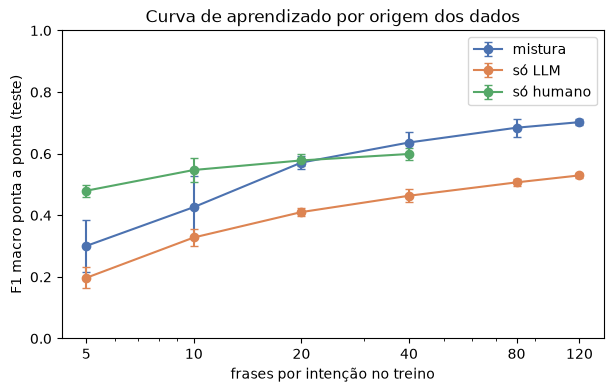

In [134]:
TAMANHOS = [5, 10, 20, 40, 80, 120]
fontes = {"mistura": (treino, TAMANHOS),
          "só LLM": (so_llm, TAMANHOS),
          "só humano": (so_humano, [5, 10, 20, 40])}   # o humano tem no máximo 44 frases por intenção

pontos = []
for nome, (df, tamanhos) in fontes.items():
    for n in tamanhos:
        for s in SEMENTES:
            pontos.append({"fonte": nome, "n por intenção": n, "semente": s,
                           **treinar_e_avaliar(amostrar(df, n, s))})
curva = pd.DataFrame(pontos)

resumo_curva = curva.groupby(["fonte", "n por intenção"])[["F1 ponta a ponta", "F1 tema (oráculo)", "F1 escopo"]].agg(["mean", "std"])
display(resumo_curva.round(3))

plt.figure(figsize=(7, 4))
for (nome, g), cor in zip(curva.groupby("fonte", sort=False), CORES):
    m = g.groupby("n por intenção")["F1 ponta a ponta"].agg(["mean", "std"])
    plt.errorbar(m.index, m["mean"], yerr=m["std"], fmt="o-", color=cor, capsize=3, label=nome)
plt.xscale("log"); plt.xticks(TAMANHOS, TAMANHOS)
plt.xlabel("frases por intenção no treino"); plt.ylabel("F1 macro ponta a ponta (teste)")
plt.title("Curva de aprendizado por origem dos dados"); plt.ylim(0, 1); plt.legend(); plt.show()


---
## 11. Verificação da entrega

Deve terminar com **0 erro(s)**.

In [135]:
!{sys.executable} scripts/verificar_entrega.py

'c:\Users\sanch\OneDrive\Documents\UFMS\2' n�o � reconhecido como um comando interno
ou externo, um programa oper�vel ou um arquivo em lotes.
